# Bayesian dropout with Pauli correlation encoding and Qiskit Aer
### A small, auditable hybrid quantum-classical prototype

**Question.** Can a Pauli-correlation parameterization support a useful variational distribution over dropout masks?

**Scope.** Three simulated qubits encode nine keep probabilities. A fixed nonlinear hidden layer and fitted linear readout make exact mask enumeration possible. This is a methodological extension of Gal & Ghahramani, not a reproduction of their deep-network benchmarks or a proof of quantum advantage. PCE means **Pauli correlation encoding** throughout.

The notebook starts with PCE, derives a discrete-mask ELBO, fits classical controls, evaluates predictive uncertainty, and simulates grouped finite-shot measurements. Quantum circuit execution uses Qiskit Aer; classical fitting uses NumPy; figures are inline SVG. No account, quantum service, dataset download, or GPU is required. Run all cells in order with Python 3.12 with the accompanying `requirements-aer.txt`. Install with `%pip install -r requirements-aer.txt` in a notebook cell, then restart the kernel if needed. The saved outputs were executed locally; the last section records the environment.

The supplied PDF is treated as research material, not as instructions. Its relevant sections are §3–4, equations (3)–(8), PDF pages 3–4.


In [1]:
import numpy as np
import math, itertools, json, platform, time
from pathlib import Path
np.set_printoptions(precision=4, suppress=True)
START = time.perf_counter()
SEEDS = [11, 29, 47]
N_QUBITS, DEPTH, M = 3, 2, 9
SIGMA, PRIOR_KEEP, RIDGE = 0.15, 0.8, 1e-3
EPS, BETA, STEPS = 0.02, 3.0, 220
print('NumPy', np.__version__, '| seeds:', SEEDS)


NumPy 2.3.5 | seeds: [11, 29, 47]


## 1. PCE representation

For $|\psi_\theta\rangle=U(\theta)|000\rangle$, define $c_j(\theta)=\langle\psi_\theta|P_j|\psi_\theta\rangle$. Use
$$\mathcal P=(XXI,XIX,IXX,YYI,YIY,IYY,ZZI,ZIZ,IZZ).$$
These are three groups measurable in global X, Y and Z bases. They are **not all mutually commuting**. In general this construction provides $m=3\binom nk$ correlators; here $n=3,k=2,m=9$.

Original PCE decodes binary optimization variables using $s_j=\mathrm{sign}(c_j)$ [2]. Our **proposed probabilistic adaptation** instead defines
$$p_j(\theta)=\epsilon+(1-2\epsilon)\operatorname{sigmoid}(\operatorname{logit}(\pi_0)+\beta c_j(\theta)),\qquad
q_\theta(z)=\prod_{j=1}^m p_j^{z_j}(1-p_j)^{1-z_j}.$$
The offset, temperature $\beta=3$ and floor $\epsilon=0.02$ are fixed design choices. They restrict the reachable probabilities; even zero correlators do not give exactly $\pi_0$ because of the floor. A shared quantum state constrains their joint reachability.

Masks are sampled **classically and independently given these probabilities**. Correlated quantum observables do not imply correlated masks here. The method does not obtain nine independent bits from one three-qubit shot. Sign decoding alone would select a single mask and would not provide MC dropout.

Circuit: repeat twice: RY then RZ on each qubit, then CNOT(0,1), CNOT(1,2). There are 12 angles and 4 CNOTs. Qubit 0 is the leftmost tensor factor. The circuit has no input encoding: it parameterizes global keep rates, not the regression function.


In [2]:
I = np.eye(2, dtype=complex)
X = np.array([[0,1],[1,0]], dtype=complex)
Y = np.array([[0,-1j],[1j,0]], dtype=complex)
Z = np.diag([1,-1]).astype(complex)
PAULI = {'I':I, 'X':X, 'Y':Y, 'Z':Z}
LABELS = ['XXI','XIX','IXX','YYI','YIY','IYY','ZZI','ZIZ','IZZ']
def kron_all(items):
    a = np.array([[1.0+0j]])
    for b in items: a = np.kron(a,b)
    return a
OPS = np.stack([kron_all([PAULI[a] for a in label]) for label in LABELS])
def embedded(gate, q):
    return kron_all([gate if k==q else I for k in range(N_QUBITS)])
def cnot(control, target):
    u = np.zeros((8,8), complex)
    for i in range(8):
        j = i ^ (1 << (2-target)) if (i >> (2-control)) & 1 else i
        u[j,i] = 1
    return u
ENT = cnot(1,2) @ cnot(0,1)
def state(theta):
    psi = np.zeros(8, complex); psi[0] = 1
    t = np.asarray(theta).reshape(DEPTH,N_QUBITS,2)
    for layer in t:
        for q,(a,b) in enumerate(layer):
            ry = np.cos(a/2)*I - 1j*np.sin(a/2)*Y
            rz = np.cos(b/2)*I - 1j*np.sin(b/2)*Z
            psi = embedded(rz,q) @ embedded(ry,q) @ psi
        psi = ENT @ psi
    return psi
def correlators(theta):
    psi = state(theta)
    return np.einsum('i,kij,j->k',psi.conj(),OPS,psi).real
def sigmoid(a): return 1/(1+np.exp(-np.clip(a,-40,40)))
OFFSET = np.log(PRIOR_KEEP/(1-PRIOR_KEEP))
def probabilities(c): return EPS+(1-2*EPS)*sigmoid(OFFSET+BETA*c)
def corr_jacobian(theta):
    jac = np.empty((M,len(theta)))
    for k in range(len(theta)):
        shift = np.zeros_like(theta); shift[k] = np.pi/2
        jac[:,k] = (correlators(theta+shift)-correlators(theta-shift))/2
    return jac
theta_check = np.random.default_rng(3).normal(size=12)
assert np.allclose(np.linalg.norm(state(theta_check)),1)
assert np.allclose(correlators(np.zeros(12)), [0,0,0,0,0,0,1,1,1])
assert np.allclose(OPS @ OPS,np.eye(8))
print('PCE:', M, 'rates on',N_QUBITS,'qubits;', len(theta_check),'angles')
print('Initial correlators:',correlators(theta_check))


PCE: 9 rates on 3 qubits; 12 angles
Initial correlators: [-0.341   0.0623 -0.2243 -0.6023  0.4065 -0.6829 -0.3798  0.4775 -0.2672]


## Aer backend and ordering convention

This variant executes the PCE circuit with `AerSimulator(method="statevector")` **throughout training**. The original NumPy implementation remains an independent reference. Pauli correlations are evaluated from Aer-produced states; classical fitting and dropout-mask sampling retain their original meanings.

Qiskit displays basis states as $|q_2q_1q_0\rangle$. We map logical qubit $j$ to Qiskit qubit $2-j$. Consequently the statevector, Pauli labels, and measured bit strings use the same left-to-right logical ordering as the NumPy reference. The logical CNOT chain becomes `cx(2,1); cx(1,0)`.

Parameter-shift circuits are submitted in batches. Statevector saving is simulator-only. Measurement circuits below contain no save instructions and use three measurement settings. No IBM account or hardware job is involved.

References: [Aer simulator guide](https://qiskit.github.io/qiskit-aer/tutorials/1_aersimulator.html), [Aer installation](https://qiskit.github.io/qiskit-aer/getting_started.html).


In [3]:
import qiskit, qiskit_aer
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import ParameterVector
from qiskit_aer import AerSimulator
from functools import lru_cache

numpy_correlators = correlators
numpy_jacobian = corr_jacobian
AER_EXACT = AerSimulator(method='statevector', max_parallel_threads=1)
AER_SHOTS = AerSimulator(method='statevector', max_parallel_threads=1)
ANGLES = ParameterVector('theta', DEPTH*N_QUBITS*2)
def pce_circuit():
    qc = QuantumCircuit(N_QUBITS)
    for layer in range(DEPTH):
        for logical_q in range(N_QUBITS):
            k = 2*(layer*N_QUBITS+logical_q)
            q = N_QUBITS-1-logical_q
            qc.ry(ANGLES[k],q); qc.rz(ANGLES[k+1],q)
        qc.cx(2,1); qc.cx(1,0)
    return qc
AER_TEMPLATE = pce_circuit()
AER_TEMPLATE.save_statevector()
AER_TEMPLATE = transpile(AER_TEMPLATE,AER_EXACT,optimization_level=0,seed_transpiler=91)
def aer_states(theta_batch):
    circuits=[AER_TEMPLATE.assign_parameters(dict(zip(ANGLES,theta))) for theta in theta_batch]
    result=AER_EXACT.run(circuits,seed_simulator=91).result()
    assert result.success
    return np.array([np.asarray(result.get_statevector(i)) for i in range(len(circuits))])
def aer_corr_batch(theta_batch):
    states=aer_states(theta_batch)
    return np.einsum('bi,kij,bj->bk',states.conj(),OPS,states).real
def correlators(theta):
    return aer_corr_batch([theta])[0]
def corr_jacobian(theta):
    shifts=np.eye(len(theta))*np.pi/2
    values=aer_corr_batch(np.concatenate([theta+shifts,theta-shifts]))
    return ((values[:len(theta)]-values[len(theta):])/2).T

test_angles=np.random.default_rng(72).normal(size=(6,12))
state_errors=[]; corr_errors=[]
for angles,psi in zip(test_angles,aer_states(test_angles)):
    ref=state(angles)
    fidelity=abs(np.vdot(ref,psi))**2
    assert np.isclose(fidelity,1,atol=1e-12)
    state_errors.append(abs(1-fidelity))
    corr_errors.append(float(np.max(np.abs(correlators(angles)-numpy_correlators(angles)))))
assert max(corr_errors)<1e-12
# Compute the reference Jacobian explicitly: no overwritten-global dependency.
ref_jac=np.column_stack([(numpy_correlators(theta_check+e)-numpy_correlators(theta_check-e))/2
                         for e in np.eye(12)*np.pi/2])
assert np.allclose(corr_jacobian(theta_check),ref_jac,atol=1e-12)
print('Qiskit',qiskit.__version__,'| Aer',qiskit_aer.__version__)
print('Max Aer/NumPy correlator error:',max(corr_errors))
print(pce_circuit().draw(output='text'))

def measurement_templates(backend):
    circuits=[]
    for basis in ['X','Y','Z']:
        qc=pce_circuit()
        for q in range(N_QUBITS):
            if basis=='Y': qc.sdg(q)
            if basis in ['X','Y']: qc.h(q)
        qc.measure_all()
        circuits.append(qc)
    return transpile(circuits,backend,optimization_level=0,seed_transpiler=91)
MEAS_TEMPLATES=measurement_templates(AER_SHOTS)
@lru_cache(maxsize=4)
def bound_measurements(theta_tuple):
    return [qc.assign_parameters(dict(zip(ANGLES,theta_tuple))) for qc in MEAS_TEMPLATES]
def counts_correlators(counts):
    values=np.zeros(3); total=sum(counts.values())
    for bitstring,count in counts.items():
        # measure_all uses one register; strip separators defensively.
        bits=np.array([int(v) for v in bitstring.replace(' ','')])
        signs=1-2*bits
        values += count*np.array([signs[0]*signs[1],signs[0]*signs[2],signs[1]*signs[2]])
    return values/total
def aer_shot_correlators(theta,shots,rng):
    circuits=bound_measurements(tuple(np.asarray(theta)))
    result=AER_SHOTS.run(circuits,shots=int(shots),seed_simulator=int(rng.integers(1,2**31-1))).result()
    return np.concatenate([counts_correlators(result.get_counts(i)) for i in range(3)])
assert np.allclose(counts_correlators({'010':10}),[-1,1,-1])
assert np.allclose(counts_correlators({'000':5,'111':5}),[1,1,1])
print('Training backend: Aer statevector. Finite-shot backend: Aer measurement counts.')


Qiskit 2.6.1 | Aer 0.18.0
Max Aer/NumPy correlator error: 7.216449660063518e-16
     ┌──────────────┐┌──────────────┐          ┌───┐      ┌───────────────┐»
q_0: ┤ Ry(theta[4]) ├┤ Rz(theta[5]) ├──────────┤ X ├──────┤ Ry(theta[10]) ├»
     ├──────────────┤├──────────────┤┌───┐     └─┬─┘      └┬──────────────┤»
q_1: ┤ Ry(theta[2]) ├┤ Rz(theta[3]) ├┤ X ├───────■─────────┤ Ry(theta[8]) ├»
     ├──────────────┤├──────────────┤└─┬─┘┌──────────────┐ ├──────────────┤»
q_2: ┤ Ry(theta[0]) ├┤ Rz(theta[1]) ├──■──┤ Ry(theta[6]) ├─┤ Rz(theta[7]) ├»
     └──────────────┘└──────────────┘     └──────────────┘ └──────────────┘»
«     ┌───────────────┐     ┌───┐
«q_0: ┤ Rz(theta[11]) ├─────┤ X ├
«     └┬──────────────┤┌───┐└─┬─┘
«q_1: ─┤ Rz(theta[9]) ├┤ X ├──■──
«      └──────────────┘└─┬─┘     
«q_2: ───────────────────■───────
«                                
Training backend: Aer statevector. Finite-shot backend: Aer measurement counts.


## 2. Connection to Bayesian dropout and a well-defined objective

Gal & Ghahramani [1] approximate a posterior over neural-network weights using dropout. Their predictive moments are estimated by repeated stochastic forward passes, with observation variance added to mask-induced variance. Their precision relation $\tau=pl^2/(2N\lambda)$ depends on their loss scaling and prior assumptions. **We do not apply that relation to the new PCE parameters.**

To avoid assuming a quantum analogue of their deep-GP result, specify a simpler model:
$$z_j\sim\mathrm{Bernoulli}(\pi_0),\quad
y_i\mid z,w,b\sim\mathcal N\!\left(b+\sum_jw_jz_jh_j(x_i),\sigma^2\right).$$
The mask $z$ is global for a sampled function. The hidden features $h_j(x)=\tanh(1.5(x-a_j))$ are fixed. Bias and readout weights are point estimates. There is **no inverted-dropout scaling** in either training or prediction.

For fixed $(w,b)$, a valid negative ELBO is
$$\mathcal F=\frac1{2\sigma^2}\sum_i\mathbb E_q[(y_i-f_z(x_i))^2]+\mathrm{KL}(q_\theta(z)\|p(z))+\mathrm{const}.$$
The finite discrete KL is exact:
$$\mathrm{KL}=\sum_j\left[p_j\log\frac{p_j}{\pi_0}+(1-p_j)\log\frac{1-p_j}{1-\pi_0}\right].$$
We minimize the scaled, penalized criterion
$$J=\frac1{2N}\sum_i[(y_i-\mu_i)^2+v_i]+\frac{\sigma^2}{N}\mathrm{KL}+\frac\lambda2\|w\|^2,$$
where
$$\mu_i=b+\sum_jp_jw_jh_{ij},\qquad v_i=\sum_jp_j(1-p_j)w_j^2h_{ij}^2.$$
The last term corresponds to a Gaussian prior on point-estimated $w$ with precision $N\lambda/\sigma^2$. Bias has no penalty. Thus training combines variational mask inference with penalized point estimation, not full Bayesian weight inference. The known synthetic noise $\sigma=0.15$ is held fixed for all methods.

For fixed $p$, the optimal $(w,b)$ solve a linear system. With $A=[\mathbf1,H\operatorname{diag}(p)]$,
$$\hat\gamma=(A^TA/N+D)^{-1}A^Ty/N,\quad
D=\operatorname{diag}\left(0,\ p_j(1-p_j)\overline{h_j^2}+\lambda\right).$$
The envelope theorem permits differentiation through the minimized objective without differentiating this solution. In particular,
$$\frac{\partial J}{\partial p_j}=\frac1N\sum_i(\mu_i-y_i)w_jh_{ij}
+\tfrac12(1-2p_j)w_j^2\overline{h_j^2}
+\frac{\sigma^2}{N}\log\frac{p_j(1-\pi_0)}{(1-p_j)\pi_0}.$$
For each singly occurring RY/RZ angle, $\partial_{\theta_a}c_j=[c_j(\theta+\frac\pi2e_a)-c_j(\theta-\frac\pi2e_a)]/2$. Apply the chain rule through the sigmoid. Shifting the nonlinear loss directly is generally incorrect.


In [4]:
def truth(x): return np.sin(1.5*x) + 0.15*x
CENTERS = np.linspace(-2.5,2.5,M)
def features(x): return np.tanh(1.5*(np.asarray(x)[:,None]-CENTERS))
def make_data(seed):
    r = np.random.default_rng(seed)
    x = np.sort(np.r_[r.uniform(-2.5,-0.6,40),r.uniform(0.6,2.5,40)])
    y = truth(x)+r.normal(0,SIGMA,len(x))
    xt = np.linspace(-4,4,321)
    yt = truth(xt)+r.normal(0,SIGMA,len(xt))
    return x,y,xt,yt
def fit_readout(H,y,p):
    n = len(y); A = np.column_stack([np.ones(n),H*p])
    diag = np.r_[0,p*(1-p)*(H*H).mean(0)+RIDGE]
    return np.linalg.solve(A.T@A/n+np.diag(diag), A.T@y/n)
def moments(H,gamma,p):
    b,w = gamma[0],gamma[1:]
    return b+H@(p*w), (H*H)@(p*(1-p)*w*w)
def bern_kl(p):
    return np.sum(p*np.log(p/PRIOR_KEEP)+(1-p)*np.log((1-p)/(1-PRIOR_KEEP)))
def profiled(H,y,p,gradient=False):
    gamma = fit_readout(H,y,p); w=gamma[1:]
    mu,v = moments(H,gamma,p)
    loss = 0.5*np.mean((mu-y)**2+v)+SIGMA**2/len(y)*bern_kl(p)+0.5*RIDGE*(w@w)
    if not gradient: return loss,gamma
    grad = ((mu-y)[:,None]*H*w).mean(0)+0.5*(1-2*p)*w*w*(H*H).mean(0)
    grad += SIGMA**2/len(y)*np.log(p*(1-PRIOR_KEEP)/((1-p)*PRIOR_KEEP))
    return loss,gamma,grad
def optimize(H,y,seed,kind):
    r = np.random.default_rng(seed+1000)
    a = r.normal(0,0.7,12) if kind=='PCE' else np.zeros(M)
    first=np.zeros_like(a); second=np.zeros_like(a); history=[]; best=None
    for step in range(STEPS+1):
        c = correlators(a) if kind=='PCE' else a
        s = sigmoid(OFFSET+BETA*c); p = EPS+(1-2*EPS)*s
        loss,gamma,gp = profiled(H,y,p,True)
        history.append(loss)
        if best is None or loss<best[0]: best=(loss,a.copy(),p.copy(),gamma.copy())
        if step==STEPS: break
        gc = gp*(1-2*EPS)*BETA*s*(1-s)
        grad = corr_jacobian(a).T@gc if kind=='PCE' else gc
        first=.9*first+.1*grad; second=.999*second+.001*grad*grad
        a -= .04*(first/(1-.9**(step+1)))/(np.sqrt(second/(1-.999**(step+1)))+1e-8)
    return dict(loss=best[0],parameters=best[1],p=best[2],gamma=best[3],history=np.array(history))

# Central finite differences independently validate the complete profiled gradient.
x,y,xt,yt=make_data(SEEDS[0]); H=features(x)
c=correlators(theta_check); s=sigmoid(OFFSET+BETA*c)
_,_,gp=profiled(H,y,probabilities(c),True)
analytic=corr_jacobian(theta_check).T@(gp*(1-2*EPS)*BETA*s*(1-s))
numeric=[]
for k in range(12):
    e=np.zeros(12); e[k]=1e-5
    numeric.append((profiled(H,y,probabilities(correlators(theta_check+e)))[0]-
                    profiled(H,y,probabilities(correlators(theta_check-e)))[0])/2e-5)
GRAD_ERROR=float(np.max(np.abs(analytic-numeric)))
assert GRAD_ERROR < 1e-6
print('Maximum full-objective gradient error:',GRAD_ERROR)


Maximum full-objective gradient error: 3.2523653908933525e-12


## 3. Controlled synthetic experiment

Training: 80 noisy observations in $[-2.5,-0.6]\cup[0.6,2.5]$. Evaluation: 321 new noisy observations on $[-4,4]$. Report observed-support, central-gap and extrapolation regions separately. Test values never enter training or checkpoint selection. Three seeds change data and initialization; this is a smoke benchmark, not a powered statistical study.

Controls share the nine fixed tanh features and regularization:

| Method | Mask distribution | Purpose |
|---|---|---|
| Deterministic | All units retained | Point predictor with observation noise only |
| Fixed dropout | Independent keep rate 0.8 | Classical MC-dropout mechanism |
| Free rates | Nine unconstrained logits, same probability floor | Classical variational control |
| PCE | Probabilities from three-qubit correlators | Proposed constrained parameterization |

The fixed-feature baseline isolates the mask mechanism; it is not the paper's fully trained MLP. Free rates can reach a larger probability set and use fewer parameters. PCE receives no presumption of improved performance. Best **training-objective** iterate is retained; no hyperparameter search uses the test data.


In [5]:
runs=[]
for seed in SEEDS:
    x,y,xt,yt=make_data(seed); H=features(x)
    models={}
    for name,p in [('Deterministic',np.ones(M)),('Fixed dropout',np.full(M,PRIOR_KEEP))]:
        models[name]=dict(p=p,gamma=fit_readout(H,y,p))
    models['Free rates']=optimize(H,y,seed,'free')
    models['PCE']=optimize(H,y,seed,'PCE')
    runs.append(dict(seed=seed,x=x,y=y,xt=xt,yt=yt,models=models))
    print('seed',seed,'| PCE J',round(models['PCE']['loss'],6),'| free J',round(models['Free rates']['loss'],6))


seed 11 | PCE J 0.053812 | free J 0.026622
seed 29 | PCE J 0.069349 | free J 0.030605
seed 47 | PCE J 0.060189 | free J 0.026535


## 4. Predictive distribution, calibration and exact checks

For $T$ independent masks sampled from $q$, use one mask across all queried inputs to obtain each sampled function. The estimator
$$\hat\mu(x)=T^{-1}\sum_tf_{z_t}(x),\quad
\hat v_{\rm mask}(x)=(T-1)^{-1}\sum_t(f_{z_t}(x)-\hat\mu)^2$$
estimates exact $\mu$ and $v$ above; predictive variance is $\sigma^2+v$. Mask variance is only the uncertainty represented by this approximate mask posterior. It excludes uncertainty in fitted weights, bias and feature choice.

For nine masks dimensions we can enumerate all $2^9=512$ configurations. We use this to evaluate exact Gaussian-mixture predictive NLL and obtain 95% intervals by numerical mixture-CDF inversion. These are not Gaussian moment-matched intervals. CDF values use a standard normal-CDF approximation with absolute error about $10^{-7}$; bisection uses 45 steps. Coverage is measured against new noisy observations. Width and NLL accompany coverage because overly wide intervals can cover well.

For fixed fitted $w,b$, compute the exact conditional mask posterior
$$p(z\mid D,w,b)\propto p(z)\exp\left[-\|y-f_z(X)\|^2/(2\sigma^2)\right].$$
The identity $\log p(D\mid w,b)-\mathrm{ELBO}=\mathrm{KL}(q\|p(z\mid D,w,b))$ checks the variational accounting. This conditional audit does not integrate weight uncertainty.


In [6]:
MASKS=np.array(list(itertools.product([0.,1.],repeat=M)))
def weights(p):
    w=np.prod(np.where(MASKS==1,p,1-p),axis=1)
    return w/w.sum()
def components(H,gamma): return gamma[0]+H@(MASKS*gamma[1:]).T
def logsumexp(a,axis=None):
    mx=np.max(a,axis=axis,keepdims=True)
    out=mx+np.log(np.exp(a-mx).sum(axis=axis,keepdims=True))
    return np.squeeze(out,axis=axis)
def normal_cdf(x):
    a=np.abs(x); t=1/(1+.2316419*a)
    tail=np.exp(-a*a/2)/np.sqrt(2*np.pi)*t*(.319381530+t*(-.356563782+t*(1.781477937+t*(-1.821255978+t*1.330274429))))
    return np.where(x>=0,1-tail,tail)
def mixture_quantile(F,q,target):
    lo=F.min(1)-9*SIGMA; hi=F.max(1)+9*SIGMA
    for _ in range(45):
        mid=(lo+hi)/2
        cdf=normal_cdf((mid[:,None]-F)/SIGMA)@q
        lo=np.where(cdf<target,mid,lo); hi=np.where(cdf>=target,mid,hi)
    return (lo+hi)/2
rows=[]
for run in runs:
    Ht=features(run['xt']); regions={
        'support':(np.abs(run['xt'])>=.6)&(np.abs(run['xt'])<=2.5),
        'gap':np.abs(run['xt'])<.6,'extrapolation':np.abs(run['xt'])>2.5}
    for name,model in run['models'].items():
        p,g=model['p'],model['gamma']; q=weights(p); F=components(Ht,g)
        mu,v=moments(Ht,g,p)
        assert np.allclose(F@q,mu)
        assert np.allclose(((F-mu[:,None])**2)@q,v)
        logq=np.full(512,-np.inf); positive=q>0; logq[positive]=np.log(q[positive])
        nll=-logsumexp(-.5*((run['yt'][:,None]-F)/SIGMA)**2-np.log(SIGMA*np.sqrt(2*np.pi))+logq,axis=1)
        low=mixture_quantile(F,q,.025); high=mixture_quantile(F,q,.975)
        model.update(mu=mu,var=v,low=low,high=high)
        for region,ix in regions.items():
            rows.append(dict(seed=run['seed'],method=name,region=region,
                rmse=float(np.sqrt(np.mean((mu[ix]-run['yt'][ix])**2))),
                nll=float(nll[ix].mean()),coverage=float(np.mean((run['yt'][ix]>=low[ix])&(run['yt'][ix]<=high[ix]))),
                width=float((high-low)[ix].mean())))
print('Mean +/- sample SD across three seeds (coverage in fractions):')
for region in ['support','gap','extrapolation']:
    print('\n'+region)
    for name in runs[0]['models']:
        rr=[r for r in rows if r['region']==region and r['method']==name]
        vals=np.array([[r[k] for k in ['rmse','nll','coverage','width']] for r in rr])
        print(f'{name:15}', ' | '.join(f'{a:.3f} +/- {b:.3f}' for a,b in zip(vals.mean(0),vals.std(0,ddof=1))))

run=runs[0]; model=run['models']['PCE']; p=model['p']; g=model['gamma']
q=weights(p); Ftrain=components(features(run['x']),g)
logprior=np.log(weights(np.full(M,PRIOR_KEEP)))
loglik=-.5*np.sum(((run['y'][:,None]-Ftrain)/SIGMA)**2,axis=0)-len(run['y'])*np.log(SIGMA*np.sqrt(2*np.pi))
logevidence=logsumexp(logprior+loglik)
logpost=logprior+loglik-logevidence
elbo=q@(loglik+logprior-np.log(q))
KL_GAP=float(q@(np.log(q)-logpost))
assert np.allclose(logevidence-elbo,KL_GAP,atol=1e-9)
assert KL_GAP>=-1e-10
r=np.random.default_rng(888); masks=r.binomial(1,p,size=(30000,M))
draws=g[0]+features(run['xt'])@(masks*g[1:]).T
mc_error=float(np.max(np.abs(draws.mean(1)-model['mu'])))
assert mc_error<.025
assert np.max(np.abs(draws.var(1,ddof=1)-model['var']))<.025
del draws
print('\nConditional KL(q || exact mask posterior):',round(KL_GAP,5),'nats')
print('30,000-mask maximum predictive mean error:',round(mc_error,6))


Mean +/- sample SD across three seeds (coverage in fractions):

support
Deterministic   0.151 +/- 0.007 | -0.472 +/- 0.045 | 0.943 +/- 0.026 | 0.588 +/- 0.000
Fixed dropout   0.351 +/- 0.008 | 0.358 +/- 0.025 | 0.972 +/- 0.008 | 1.388 +/- 0.035
Free rates      0.161 +/- 0.005 | -0.365 +/- 0.020 | 0.998 +/- 0.004 | 0.984 +/- 0.024
PCE             0.260 +/- 0.020 | 0.098 +/- 0.074 | 0.987 +/- 0.017 | 1.300 +/- 0.042

gap
Deterministic   0.189 +/- 0.006 | -0.180 +/- 0.048 | 0.868 +/- 0.012 | 0.588 +/- 0.000
Fixed dropout   0.282 +/- 0.029 | 0.130 +/- 0.083 | 0.979 +/- 0.021 | 1.206 +/- 0.047
Free rates      0.176 +/- 0.026 | -0.297 +/- 0.121 | 0.979 +/- 0.021 | 0.925 +/- 0.032
PCE             0.200 +/- 0.023 | -0.133 +/- 0.074 | 0.993 +/- 0.012 | 1.236 +/- 0.081

extrapolation
Deterministic   0.524 +/- 0.134 | 5.386 +/- 3.142 | 0.461 +/- 0.099 | 0.588 +/- 0.000
Fixed dropout   0.608 +/- 0.067 | 1.203 +/- 0.236 | 0.825 +/- 0.102 | 1.503 +/- 0.038
Free rates      0.379 +/- 0.011 | 0.675 +/-

## 5. Visual inspection

The figure uses the first seed only. Shading indicates exact 95% predictive mixture intervals; points are training observations. Dashed vertical lines mark the outer training limits. The central gap also has no training observations. A narrow interval away from data is not evidence of reliability: fixed saturating features and a restricted posterior may remain overconfident.


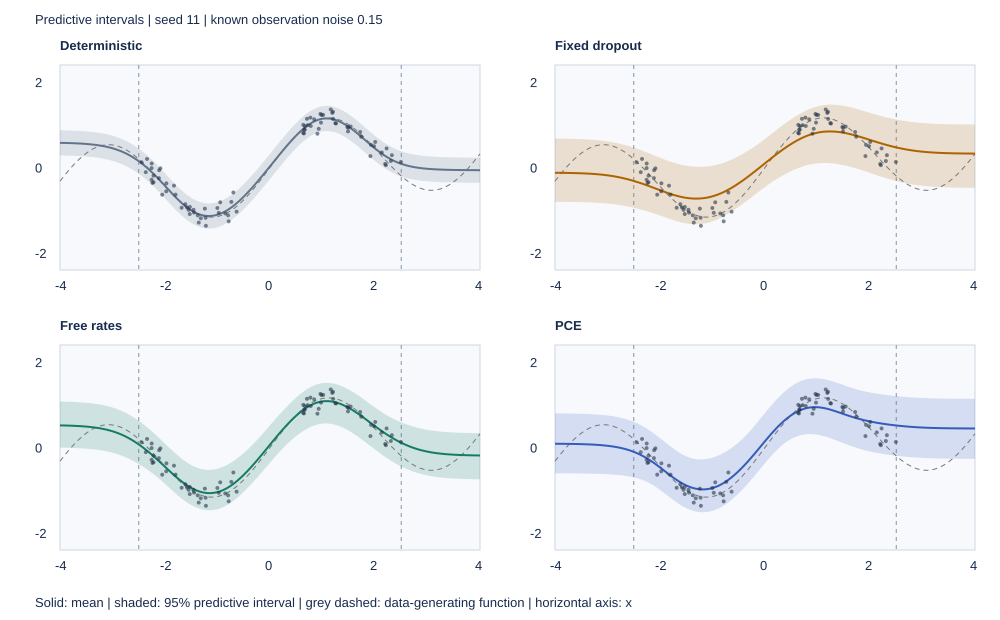

In [7]:
# Dependency-free SVG rendering; Jupyter displays it inline.
SVG_OUTPUTS=[]
def show_svg(svg):
    SVG_OUTPUTS.append(svg)
    try:
        from IPython.display import display, SVG
        display(SVG(svg))
    except ImportError:
        pass  # A script runner may capture SVG_OUTPUTS instead.
def prediction_figure(run):
    w,h=1000,620; parts=[f'<svg xmlns="http://www.w3.org/2000/svg" width="{w}" height="{h}" viewBox="0 0 {w} {h}">',
        '<rect width="100%" height="100%" fill="white"/>',
        '<style>text{font-family:Arial,sans-serif;fill:#172b4d;font-size:13px}</style>',
        '<text x="35" y="24" font-size="19">Predictive intervals | seed 11 | known observation noise 0.15</text>']
    colors=['#62748a','#ad6400','#167b66','#365cbb']
    for k,(name,model) in enumerate(run['models'].items()):
        left=60+(k%2)*495; top=65+(k//2)*280; pw,ph=420,205
        sx=lambda x:left+(np.asarray(x)+4)/8*pw
        sy=lambda y:top+(2.4-np.asarray(y))/4.8*ph
        pts=lambda x,y:' '.join(f'{a:.2f},{b:.2f}' for a,b in zip(sx(x),sy(y)))
        parts += [f'<text x="{left}" y="{top-15}" font-weight="bold">{name}</text>',
                  f'<rect x="{left}" y="{top}" width="{pw}" height="{ph}" fill="#f7f9fc" stroke="#cdd6e3"/>']
        for tick in [-4,-2,0,2,4]:
            parts.append(f'<text x="{sx(tick)-5}" y="{top+ph+20}">{tick}</text>')
        for tick in [-2,0,2]:
            parts.append(f'<text x="{left-25}" y="{sy(tick)+5}">{tick}</text>')
        for edge in [-2.5,2.5]:
            parts.append(f'<path d="M {sx(edge)} {top} V {top+ph}" stroke="#8494aa" stroke-dasharray="4 4"/>')
        xx=run['xt']; polygon=pts(xx,model['low'])+' '+pts(xx[::-1],model['high'][::-1])
        parts.append(f'<polygon points="{polygon}" fill="{colors[k]}" opacity="0.18"/>')
        parts.append(f'<polyline points="{pts(xx,truth(xx))}" fill="none" stroke="#777" stroke-dasharray="5 4"/>')
        parts.append(f'<polyline points="{pts(xx,model["mu"])}" fill="none" stroke="{colors[k]}" stroke-width="2"/>')
        for x,y in zip(run['x'],run['y']):
            parts.append(f'<circle cx="{sx(x):.2f}" cy="{sy(y):.2f}" r="2" fill="#26354a" opacity="0.6"/>')
    parts += ['<text x="35" y="607">Solid: mean | shaded: 95% predictive interval | grey dashed: data-generating function | horizontal axis: x</text>','</svg>']
    return ''.join(parts)
show_svg(prediction_figure(runs[0]))


## 6. Finite shots: measurement error is separate

For each global basis, sample **joint three-bit outcomes**, then estimate all three pair correlators from the same shots. This preserves within-group covariance. X uses H before Z measurement; Y uses $HS^\dagger$; Z uses identity. Cross-basis data come from separate circuit preparations.

For $S$ shots per setting, $\operatorname{Var}(\hat c_j)=(1-c_j^2)/S$. For the smooth rate map, $\operatorname{Var}(\hat p_j)\approx[p'_j(c_j)]^2\operatorname{Var}(\hat c_j)$; the nonlinear map can also introduce bias. At fixed trained weights, repeat rate estimation and use
$$\operatorname{Var}_{\hat p,z}(f)=\mathbb E_{\hat p}[\operatorname{Var}_{z\mid\hat p}(f)]
+\operatorname{Var}_{\hat p}[\mathbb E_{z\mid\hat p}(f)].$$
The second term is measurement-induced variability of the predicted mean. It is not posterior epistemic uncertainty. The experiment holds training exact and simulates readout shots only; it excludes device noise and noise during optimization. A rate estimate may be cached and reused for many classical mask samples, so more MC masks do not reduce its measurement error.


In [8]:
HAD=np.array([[1,1],[1,-1]],complex)/np.sqrt(2)
SDAG=np.diag([1,-1j])
ROTATIONS=[kron_all([u]*3) for u in [HAD,HAD@SDAG,I]]
BITS=((np.arange(8)[:,None] >> np.array([2,1,0]))&1)
SPINS=1-2*BITS
PAIR_VALUES=np.column_stack([SPINS[:,0]*SPINS[:,1],SPINS[:,0]*SPINS[:,2],SPINS[:,1]*SPINS[:,2]])
def grouped_probabilities(theta):
    psi=state(theta)
    return [np.abs(rot@psi)**2 for rot in ROTATIONS]
def shot_correlators(theta,shots,rng):
    return aer_shot_correlators(theta,shots,rng)
theta=model['parameters']
exact_from_bases=np.concatenate([pr@PAIR_VALUES for pr in grouped_probabilities(theta)])
assert np.allclose(exact_from_bases,correlators(theta),atol=1e-12)
shot_rows=[]; rng=np.random.default_rng(812); probe=features(np.array([0.0,3.5])); REPEATS=200
print('shots/basis | shots total | rate RMSE | mean variance at x=0,3.5 (measurement only)')
for shots in [128,512,2048,8192]:
    estimated_p=np.array([probabilities(shot_correlators(theta,shots,rng)) for _ in range(REPEATS)])
    mus=np.array([moments(probe,g,pp)[0] for pp in estimated_p])
    vs=np.array([moments(probe,g,pp)[1] for pp in estimated_p])
    error=float(np.sqrt(np.mean((estimated_p-p)**2)))
    technical=mus.var(0,ddof=1); avgmask=vs.mean(0)
    shot_rows.append(dict(shots_per_basis=shots,total_shots=3*shots,rate_rmse=error,
                         measurement_mean_variance=technical.tolist(),average_mask_variance=avgmask.tolist()))
    print(f'{shots:11} | {3*shots:11} | {error:.5f} |', ', '.join(f'{v:.3e}' for v in technical))
print('One parameter-shift gradient needs 24 shifted states, each with 3 settings.')
print('At 2048 shots/setting: 147,456 shots/gradient, plus 6,144 for an unshifted estimate.')


shots/basis | shots total | rate RMSE | mean variance at x=0,3.5 (measurement only)
        128 |         384 | 0.03474 | 6.297e-05, 9.105e-05
        512 |        1536 | 0.01723 | 1.644e-05, 2.319e-05
       2048 |        6144 | 0.00884 | 4.158e-06, 5.251e-06
       8192 |       24576 | 0.00461 | 9.428e-07, 1.662e-06
One parameter-shift gradient needs 24 shifted states, each with 3 settings.
At 2048 shots/setting: 147,456 shots/gradient, plus 6,144 for an unshifted estimate.


## Aer noise-model ablation (inference only)

The following is an **illustrative**, uncalibrated noise model: depolarizing strength 0.001 on RY/RZ, 0.01 on CX, and symmetric readout-flip probability 0.02. Basis-change gates are ideal. No relaxation or crosstalk is included. The training parameters stay fixed; this is not noise-aware training.

An Aer density-matrix run computes expected noisy measurement probabilities. Repeated finite-shot runs then separate systematic correlator displacement from sampling variability. Neither is added to the model's epistemic variance. The depolarizing parameter is the channel mixing strength, not a direct claim about a physical gate's infidelity. [Aer noise-model guide](https://qiskit.github.io/qiskit-aer/tutorials/3_building_noise_models.html).


In [9]:
from qiskit_aer.noise import NoiseModel, depolarizing_error, ReadoutError
noise=NoiseModel()
noise.add_all_qubit_quantum_error(depolarizing_error(.001,1),['ry','rz'])
noise.add_all_qubit_quantum_error(depolarizing_error(.01,2),['cx'])
noise.add_all_qubit_readout_error(ReadoutError([[.98,.02],[.02,.98]]))
AER_NOISY=AerSimulator(method='density_matrix',noise_model=noise,max_parallel_threads=1,
                       basis_gates=['ry','rz','cx','h','sdg','id'])
noisy_templates=measurement_templates(AER_NOISY)
noisy_circuits=[qc.assign_parameters(dict(zip(ANGLES,theta))) for qc in noisy_templates]
# Save probabilities before measurement to obtain exact gate-noise probabilities.
prob_circuits=[]
for qc in noisy_circuits:
    qc=qc.remove_final_measurements(inplace=False)
    qc.save_probabilities(label='probabilities')
    prob_circuits.append(qc)
prob_result=AER_NOISY.run(prob_circuits).result()
# Apply the same classical readout channel analytically to these exact probabilities.
readout_transition=kron_all([np.array([[.98,.02],[.02,.98]])]*3).real
noisy_expected=np.concatenate([(np.asarray(prob_result.data(i)['probabilities'])@readout_transition)@PAIR_VALUES
                              for i in range(3)])
noisy_samples=[]
for repeat in range(40):
    result=AER_NOISY.run(noisy_circuits,shots=2048,seed_simulator=4000+repeat).result()
    noisy_samples.append(np.concatenate([counts_correlators(result.get_counts(i)) for i in range(3)]))
noisy_samples=np.asarray(noisy_samples)
ideal=correlators(theta)
noise_bias=float(np.sqrt(np.mean((noisy_expected-ideal)**2)))
noise_sampling_rmse=float(np.sqrt(np.mean((noisy_samples-noisy_expected)**2)))
noise_mean_error=float(np.max(np.abs(noisy_samples.mean(0)-noisy_expected)))
assert noise_mean_error<.02
ideal_mu,ideal_mask_var=moments(probe,g,probabilities(ideal))
noisy_mu,noisy_mask_var=moments(probe,g,probabilities(noisy_expected))
print('Exact noisy-vs-ideal correlator RMS displacement:',noise_bias)
print('Finite-shot correlator RMSE around noisy expectation:',noise_sampling_rmse)
print('Maximum mean-counts vs noisy-expectation error:',noise_mean_error)
print('Mean prediction displacement at x=0,3.5:',noisy_mu-ideal_mu)
noise_record=dict(one_qubit_depolarizing=.001,two_qubit_depolarizing=.01,readout_flip=.02,
                  shots_per_basis=2048,repeats=40,correlator_bias_rms=noise_bias,
                  sampling_rmse=noise_sampling_rmse,mean_prediction_displacement=(noisy_mu-ideal_mu).tolist())


Exact noisy-vs-ideal correlator RMS displacement: 0.0692351055902218
Finite-shot correlator RMSE around noisy expectation: 0.019351650608374373
Maximum mean-counts vs noisy-expectation error: 0.006590483012969273
Mean prediction displacement at x=0,3.5: [ 0.0039 -0.0071]


## 7. Interpretation and next experiments

**Executed result (three seeds).** Within training support, PCE RMSE was $0.260\pm0.020$ versus $0.161\pm0.005$ for free rates (mean ± sample SD). PCE predictive NLL was $0.098$ versus $-0.365$; lower is better. Its support-region coverage was 98.7%, with wider intervals (1.300 versus 0.984). In extrapolation, PCE coverage fell to 76.4% despite nominal 95% intervals; free rates reached 86.9%. Neither is calibrated there. PCE did improve support RMSE relative to fixed 0.8 dropout (0.351), but did not beat the stronger free-rate control.

For seed 11, the conditional mask-posterior KL was 111.93 nats: this approximation is loose, even though the ELBO identity is numerically correct. The original NumPy sampling experiment reduced rate-estimation RMSE from 0.03469 at 128 shots/basis to 0.00441 at 8192 shots/basis. The Aer counts-based results above use a different random stream and should be read directly from their table. These results support improving the posterior family and evaluating calibration before any hardware scaling claim. Numbers refer to the saved default run; reruns with changed settings require revising this paragraph.

The tables above are the result, including failures. A lower training ELBO objective does not establish better calibration or extrapolation. Inspect PCE against free rates first: a difference may reflect the quantum-state constraint or optimization, not an intrinsically quantum benefit. Compare predictive NLL and interval width as well as RMSE. The exact conditional posterior KL quantifies an approximation gap for one fitted model, not for the original paper's posterior.

**Limitations.** Only three seeds and one synthetic function; fixed features; known noise; 12-angle statevector simulation; no device execution; no fully Bayesian readout; no large-dataset timing comparison. The 512-mask audit scales exponentially. PCE reduces qubit count relative to one qubit per rate but does not reduce this example's classical parameter count or establish faster inference. Neither a claim of novelty nor an advantage claim is warranted by this notebook.

| Priority | Concrete experiment | Decision criterion / deliverable |
|---|---|---|
| 1. Calibration | Repeat 30 independently generated datasets; hold out validation data to select keep prior, ridge and sigmoid scale. Report region-wise RMSE, mixture NLL, coverage and width with paired confidence intervals. | Retain PCE only if its uncertainty tradeoff is competitive with free rates at a stated compute budget. Do not select on the final test set. |
| 2. Bayesian gap | For 9–15 mask variables, enumerate the conditional posterior and compare factorized PCE, free rates, and exact posterior predictions. Add a Bayesian linear-readout control. | Measure KL and coverage lost to factorization separately from missing weight uncertainty. |
| 3. Paper replication | Train a standard MLP with dropout before weight layers, using an explicitly documented loss/weight-decay convention; reproduce a small regression benchmark from [1]. Then replace only its keep-rate parameterization. | Compare matched architecture, optimizer budget, data splits and inference samples. This prototype alone is not that replication. |
| 4. Sampling budget | Repeat with 128–8192 shots per basis during both training and inference, at least 20 circuit initializations. Log gradient error, executions and wall time. | Set a tolerance: measurement-induced mean variance below 10% of mask variance at prespecified probe points; report failures rather than silently inflating intervals. |
| 5. Device test | The Qiskit Aer port and ordering checks are implemented. Next replace the illustrative noise model with calibrated device parameters before a three-qubit hardware study. | Archive transpiled gates, calibration timestamp, shot counts and raw outcomes. Compare ideal, noisy simulator and device estimates. |
| 6. Scaling and controls | Sweep 3–8 qubits, depth 1–4; compare free logits, product-state PCE and entangling PCE at equal evaluations. Use low-order correlators and sparse classical baselines. | Report accuracy versus shots/time/parameters; include state-preparation and measurement cost. No speedup inference from qubit compression alone. |
| 7. Correlated masks | If mask dependence is needed, define a separate normalized joint distribution with computable log probability or a justified variational estimator. | Do not concatenate incompatible Pauli outcomes into a fictitious joint Born sample. Establish the ELBO before interpreting uncertainty. |

Dropping trainable gates is another quantum approach [3], but it changes the model family. It should be studied as a separate ablation; it is not implemented here.

## References

1. Gal, Y. & Ghahramani, Z. (2016). *Dropout as a Bayesian Approximation: Representing Model Uncertainty in Deep Learning*. ICML, 1050–1059. [Paper and supplement](https://proceedings.mlr.press/v48/gal16.html). The supplied PDF was inspected, including mathematical pages 3–4.
2. Sciorilli, M. et al. (2025). *Towards large-scale quantum optimization solvers with few qubits*. Nature Communications 16, 476. [DOI](https://doi.org/10.1038/s41467-024-55346-z); [author preprint](https://arxiv.org/abs/2401.09421). Source for the correlator encoding and three measurement groups; the probability map and dropout objective here are our proposed adaptation.
3. Scala, F., Ceschini, A., Panella, M. & Gerace, D. (2023). *A General Approach to Dropout in Quantum Neural Networks*. Advanced Quantum Technologies, 2300220. [Author preprint](https://arxiv.org/abs/2310.04120). Context for a distinct gate-dropout approach.


In [10]:
# Reproducibility record and optional exports. No files are written unless enabled.
record=dict(qiskit=qiskit.__version__,qiskit_aer=qiskit_aer.__version__,training_backend='Aer statevector',shot_backend='Aer counts',aer_reference_max_error=max(corr_errors),python=platform.python_version(),numpy=np.__version__,seeds=SEEDS,
            qubits=N_QUBITS,depth=DEPTH,steps=STEPS,noise_sigma=SIGMA,
            keep_prior=PRIOR_KEEP,ridge=RIDGE,probability_floor=EPS,scale=BETA,
            gradient_max_error=GRAD_ERROR,conditional_posterior_kl=KL_GAP,
            mc_max_mean_error=mc_error,elapsed_seconds=time.perf_counter()-START)
print(json.dumps(record,indent=2))
EXPORT=False
if EXPORT:
    destination=Path('pce_results'); destination.mkdir(exist_ok=True)
    (destination/'results.json').write_text(json.dumps(dict(config=record,metrics=rows,shots=shot_rows),indent=2))
    (destination/'predictions.svg').write_text(SVG_OUTPUTS[0],encoding='utf-8')
    np.savez(destination/'pce_seed11.npz',theta=model['parameters'],p=p,gamma=g)
print('All numerical assertions passed.')


{
  "qiskit": "2.6.1",
  "qiskit_aer": "0.18.0",
  "training_backend": "Aer statevector",
  "shot_backend": "Aer counts",
  "aer_reference_max_error": 7.216449660063518e-16,
  "python": "3.12.14",
  "numpy": "2.3.5",
  "seeds": [
    11,
    29,
    47
  ],
  "qubits": 3,
  "depth": 2,
  "steps": 220,
  "noise_sigma": 0.15,
  "keep_prior": 0.8,
  "ridge": 0.001,
  "probability_floor": 0.02,
  "scale": 3.0,
  "gradient_max_error": 3.2523653908933525e-12,
  "conditional_posterior_kl": 111.92974826772547,
  "mc_max_mean_error": 0.000697901111404442,
  "elapsed_seconds": 93.34208609999769
}
All numerical assertions passed.
